# Tugas Besar Deep Learning — Klasifikasi Jenis Sampah (TrashNet)
## Baseline CNN *from scratch* vs. Transfer Learning EfficientNetB0

**Masalah bisnis.** Pemilahan sampah di TPS3R, bank sampah, dan fasilitas daur ulang (MRF) masih banyak dilakukan manual. Prosesnya lambat, tidak konsisten, dan berisiko bagi petugas. Selain itu, sampah daur ulang yang terkontaminasi jenis lain turun nilai jualnya. Model klasifikasi citra yang mengenali jenis sampah dari foto dapat menjadi dasar sistem pemilahan otomatis atau asisten pemilahan (aplikasi web/kamera) yang mempercepat proses dan meningkatkan kemurnian material daur ulang.

**Dataset.** [`garythung/trashnet`](https://huggingface.co/datasets/garythung/trashnet) di Hugging Face: ±2,5 ribu foto sampah tunggal berlatar putih dalam 6 kelas: *cardboard, glass, metal, paper, plastic, trash*. Repositori berisi file zip (`dataset-resized.zip`, folder per kelas) tanpa pembagian split, jadi pembagian train/validasi/uji dilakukan di notebook ini.

**Alur notebook**
1. Setup & konfigurasi (seed, path, hyperparameter)
2. Memuat data dan eksplorasi (EDA)
3. Pembersihan (deteksi duplikat untuk mencegah kebocoran data) dan pembagian stratified 70/15/15
4. Pra-pemrosesan (resize 224×224) dan augmentasi
5. Model **baseline**: CNN dari nol. Model **usulan**: EfficientNetB0 (ImageNet) + fine-tuning bertahap
6. Pelatihan dengan **3 seed** untuk setiap konfigurasi, termasuk **studi ablasi** (tanpa fine-tuning, tanpa augmentasi)
7. Evaluasi dengan protokol yang sama: accuracy, macro precision/recall/F1 (rerata ± std), jumlah parameter, waktu inferensi, uji McNemar
8. Analisis galat (confusion matrix, salah prediksi) dan explainability (Grad-CAM)
9. Menyimpan model terbaik ke format **.h5**, lalu memverifikasi bahwa model dapat dimuat ulang

> **Runtime yang disarankan:** Google Colab dengan GPU (Runtime → Change runtime type → T4 GPU). Seluruh eksperimen (9 run) memakan waktu sekitar 2–3 jam di T4. Hasil setiap run disimpan ke Google Drive, jadi kalau sesi terputus, jalankan ulang notebook dan run yang sudah selesai akan dilewati (*resume*).

## 1. Setup Lingkungan

In [1]:
import sys, subprocess, importlib
for pkg in ["huggingface_hub"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import os, io, json, time, math, hashlib, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from scipy.stats import binomtest

import tensorflow as tf
import keras
from keras import layers, regularizers

from huggingface_hub import hf_hub_download
import zipfile

print("Python      :", sys.version.split()[0])
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU         :", gpus if gpus else "TIDAK ADA (training akan sangat lambat)")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

Python      : 3.13.16
TensorFlow  : 2.21.0
Keras       : 3.13.2
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.1 Konfigurasi
Semua hyperparameter ada di sel ini supaya mudah dilaporkan di **Tabel 3** laporan. Di Colab, Google Drive di-mount agar hasil (bobot, metrik, gambar) tetap ada walaupun sesi terputus.

In [3]:
IN_COLAB = "google.colab" in sys.modules
# Data SELALU diunduh dari Hugging Face (HF_DATASET di bawah), tidak perlu Drive.
# Drive hanya opsional untuk menyimpan hasil agar tahan jika sesi Colab terputus.
USE_DRIVE = False             # True = simpan hasil ke Google Drive (disarankan karena training lama)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/tubes_dl_trashnet")
elif IN_COLAB:
    OUTPUT_DIR = Path("/content/outputs")   # hilang jika runtime di-reset; unduh zip di akhir notebook
else:
    OUTPUT_DIR = Path("outputs")

# Gambar hasil ekspor disimpan di disk lokal agar I/O cepat (dibuat ulang otomatis tiap sesi)
DATA_DIR  = Path("/content/data/trashnet_224") if IN_COLAB else Path("data/trashnet_224")
RUNS_DIR  = OUTPUT_DIR / "runs"      # bobot + metrik per run (untuk resume)
FIG_DIR   = OUTPUT_DIR / "figures"   # gambar untuk laporan
TAB_DIR   = OUTPUT_DIR / "tables"    # tabel untuk laporan
MODEL_DIR = OUTPUT_DIR / "models"    # model final .h5
for d in [DATA_DIR, RUNS_DIR, FIG_DIR, TAB_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

HF_DATASET  = "garythung/trashnet"   # https://huggingface.co/datasets/garythung/trashnet
IMG_SIZE    = 224
BATCH_SIZE  = 32
SPLIT_SEED  = 42                 # seed pembagian data (tetap untuk semua eksperimen)
SEEDS       = [42, 123, 2024]    # >= 3 seed untuk rerata ± std
VAL_SIZE    = 0.15
TEST_SIZE   = 0.15
LABEL_SMOOTHING   = 0.1
USE_CLASS_WEIGHTS = True         # kelas 'trash' jauh lebih sedikit
BACKBONE_WEIGHTS  = "imagenet"

BASELINE_CFG = dict(
    optimizer="Adam", lr=1e-3, epochs=80, patience=12,
    filters=[32, 64, 128, 256], dense_units=256, dropout=0.4, l2=1e-4,
)
PROPOSED_CFG = dict(
    optimizer="Adam",
    # Tahap 1: backbone dibekukan, hanya head yang dilatih
    stage1_lr=1e-3, stage1_epochs=20, stage1_patience=5,
    # Tahap 2: fine-tuning blok atas backbone (mulai block4a), BatchNorm tetap beku
    stage2_lr=1e-5, stage2_epochs=40, stage2_patience=8,
    fine_tune_at="block4a_expand_conv",
    dropout=0.3,
)
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())

OUTPUT_DIR: /kaggle/working/outputs


In [4]:
def set_seed(seed: int):
    # Mengunci seed Python, NumPy, dan TensorFlow
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)

set_seed(SPLIT_SEED)

## 2. Memuat Dataset dan Eksplorasi Data (EDA)
File zip dataset diunduh langsung dari Hugging Face Hub (`hf_hub_download`), lalu diekstrak. Label diambil dari **nama folder kelas** di dalam zip. `load_dataset` sengaja tidak dipakai karena repositori ini hanya berisi zip dan tebakan labelnya gagal di beberapa versi library (`Invalid string class label trashnet@...`).

Dipakai `dataset-resized.zip` (±43 MB, foto 512×384), bukan `dataset-original.zip` (3,6 GB), karena model memakai input 224×224. Hash MD5 dan ukuran gambar dihitung untuk deteksi duplikat.

In [5]:
ZIP_NAME = "dataset-resized.zip"
ZIP_PATH = hf_hub_download(HF_DATASET, ZIP_NAME, repo_type="dataset")
print("Zip:", ZIP_PATH)

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Zip: /root/.cache/huggingface/hub/datasets--garythung--trashnet/snapshots/94cd17ebfd6702bf62281d3c89f22ff649815b46/dataset-resized.zip


In [6]:
CLASS_NAMES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
NUM_CLASSES = len(CLASS_NAMES)

RAW_DIR = DATA_DIR.parent / "raw"
if RAW_DIR.exists():
    shutil.rmtree(RAW_DIR)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(RAW_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png"}
IMAGE_PATHS = sorted(p for p in RAW_DIR.rglob("*")
                     if p.suffix.lower() in IMG_EXT and p.parent.name in CLASS_NAMES and "__MACOSX" not in p.parts)
assert len(IMAGE_PATHS) > 0, "Tidak ada gambar ditemukan; periksa struktur zip: " + str([p.name for p in RAW_DIR.iterdir()])
print("Kelas:", CLASS_NAMES)
print("Folder di zip:", sorted({p.parent.name for p in RAW_DIR.rglob('*') if p.is_dir()})[:12])

records = []
for i, p in enumerate(IMAGE_PATHS):
    b = p.read_bytes()
    with Image.open(io.BytesIO(b)) as im:
        w, h = im.size
        fmt, mode = im.format, im.mode
    lab = CLASS_NAMES.index(p.parent.name)
    records.append(dict(idx=i, label=lab, cls=p.parent.name,
                        md5=hashlib.md5(b).hexdigest(), width=w, height=h,
                        fmt=fmt, mode=mode, kbytes=len(b) / 1024))
meta = pd.DataFrame(records)
print("Jumlah gambar:", len(meta))
meta.head()

Kelas: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Folder di zip: ['__MACOSX', 'dataset-resized', 'raw']
Jumlah gambar: 2527


,idx,label,cls,md5,width,height,fmt,mode,kbytes
0,0,0,cardboard,336f2740cc7c60ac7544ad47e34dc602,512,384,JPEG,RGB,16.926758
1,1,0,cardboard,b37669c0dcf8eb3939bb35c7be9796fb,512,384,JPEG,RGB,21.174805
2,2,0,cardboard,fb79c3308ad68dbac1cf23c244fc0fa5,512,384,JPEG,RGB,14.535156
3,3,0,cardboard,733b19b0875874a4804dc2b3bf7a2c08,512,384,JPEG,RGB,13.954102
4,4,0,cardboard,eded15aa90832e6144fccb292448ef43,512,384,JPEG,RGB,17.592773


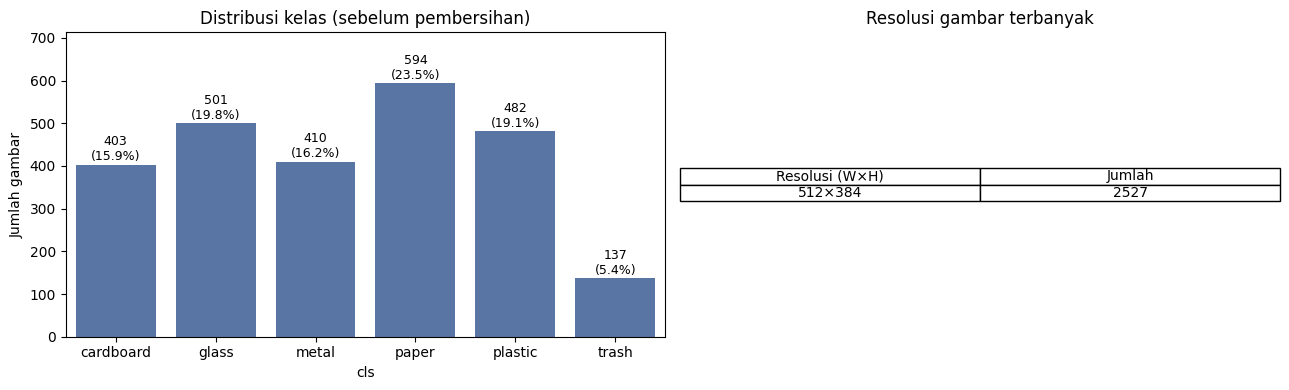

Format : {'JPEG': 2527}
Mode   : {'RGB': 2527}
Rasio imbalance (maks/min): 4.34


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = meta["cls"].value_counts().reindex(CLASS_NAMES)
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color="#4C72B0")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 10, f"{v}\n({v/len(meta):.1%})", ha="center", fontsize=9)
axes[0].set_title("Distribusi kelas (sebelum pembersihan)")
axes[0].set_ylabel("Jumlah gambar"); axes[0].set_ylim(0, counts.max() * 1.2)

size_counts = meta.groupby(["width", "height"]).size().sort_values(ascending=False)
axes[1].axis("off")
axes[1].table(cellText=[[f"{w}×{h}", n] for (w, h), n in size_counts.head(8).items()],
              colLabels=["Resolusi (W×H)", "Jumlah"], loc="center", cellLoc="center")
axes[1].set_title("Resolusi gambar terbanyak")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_distribusi_kelas.png", dpi=200, bbox_inches="tight"); plt.show()

print("Format :", meta["fmt"].value_counts().to_dict())
print("Mode   :", meta["mode"].value_counts().to_dict())
print("Rasio imbalance (maks/min): %.2f" % (counts.max() / counts.min()))

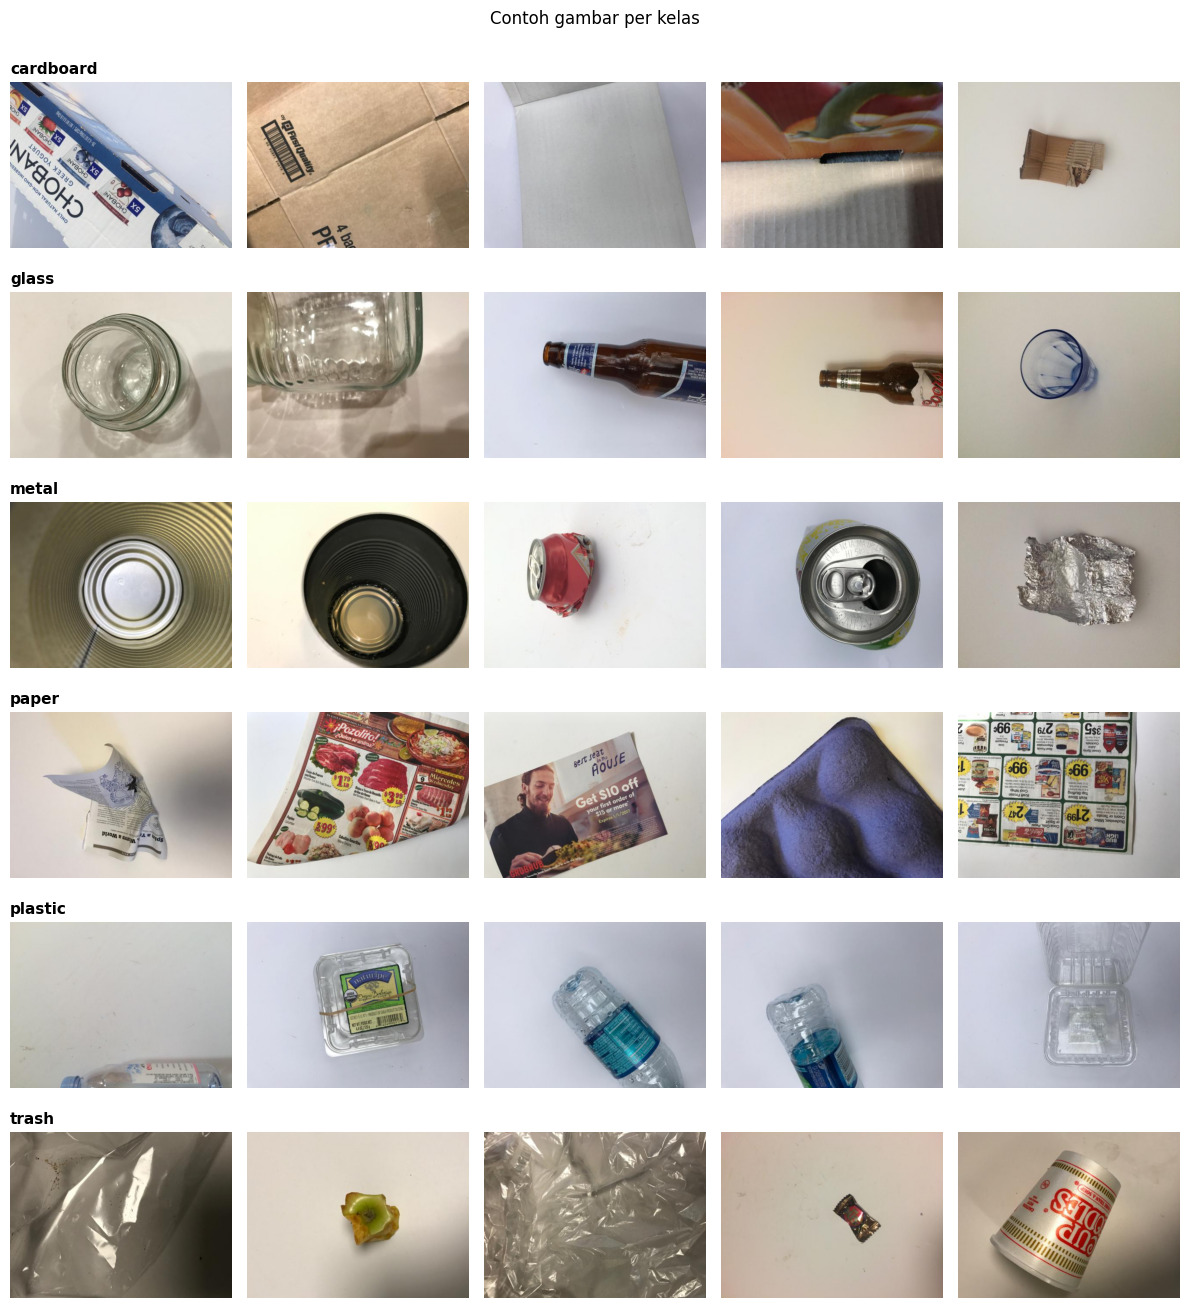

In [8]:
def decode_hf(idx):
    return ImageOps.exif_transpose(Image.open(IMAGE_PATHS[int(idx)])).convert("RGB")

n_show = 5
fig, axes = plt.subplots(NUM_CLASSES, n_show, figsize=(n_show * 2.4, NUM_CLASSES * 2.2))
for r, c in enumerate(CLASS_NAMES):
    sample_idx = meta[meta["cls"] == c].sample(n_show, random_state=SPLIT_SEED)["idx"]
    for k, idx in enumerate(sample_idx):
        axes[r, k].imshow(decode_hf(idx)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Contoh gambar per kelas", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_contoh_gambar.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Pembersihan Data dan Pembagian Train/Validasi/Uji
**Pencegahan kebocoran data.** Gambar yang identik (hash MD5 sama) bisa terbagi ke train dan uji, sehingga skor uji terlihat lebih tinggi dari kenyataan. Karena itu duplikat dihapus *sebelum* pembagian. Jika ada duplikat dengan label berbeda (label ambigu), semua salinannya dibuang.

Data kemudian dibagi **stratified 70/15/15** dengan seed tetap, sehingga semua model dan semua seed pelatihan memakai data uji yang sama persis.

In [9]:
dup_mask = meta.duplicated("md5", keep=False)
dup_groups = meta[dup_mask].groupby("md5")["label"].nunique()
conflict_md5 = set(dup_groups[dup_groups > 1].index)

print(f"Gambar yang punya duplikat identik : {dup_mask.sum()} ({meta[dup_mask]['md5'].nunique()} grup)")
print(f"Grup duplikat dengan label berbeda : {len(conflict_md5)}")

clean = meta[~meta["md5"].isin(conflict_md5)].drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Jumlah gambar setelah pembersihan  : {len(clean)} (dibuang {len(meta) - len(clean)})")

Gambar yang punya duplikat identik : 6 (3 grup)
Grup duplikat dengan label berbeda : 3
Jumlah gambar setelah pembersihan  : 2521 (dibuang 6)


In [10]:
train_df, temp_df = train_test_split(clean, test_size=VAL_SIZE + TEST_SIZE,
                                     stratify=clean["label"], random_state=SPLIT_SEED)
val_df, test_df = train_test_split(temp_df, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                                   stratify=temp_df["label"], random_state=SPLIT_SEED)
train_df, val_df, test_df = [d.sort_values("idx").reset_index(drop=True) for d in (train_df, val_df, test_df)]

# Pastikan tidak ada irisan antar-split
assert not (set(train_df.md5) & set(val_df.md5)) and not (set(train_df.md5) & set(test_df.md5)) \
       and not (set(val_df.md5) & set(test_df.md5)), "Kebocoran data terdeteksi!"

table2 = pd.DataFrame({
    "Train":   train_df["cls"].value_counts(),
    "Validasi": val_df["cls"].value_counts(),
    "Uji":     test_df["cls"].value_counts(),
}).reindex(CLASS_NAMES)
table2["Total"] = table2.sum(axis=1)
table2.loc["Total"] = table2.sum()
table2.index.name = "Kelas"
table2.to_csv(TAB_DIR / "tabel2_distribusi_split.csv")
pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")]) \
  [["idx", "md5", "label", "cls", "split"]].to_csv(TAB_DIR / "split_indices.csv", index=False)
print("Tabel 2. Distribusi data per kelas")
table2

Tabel 2. Distribusi data per kelas


,Train,Validasi,Uji,Total
Kelas,,,,
cardboard,282,60,61,403
glass,348,75,75,498
metal,286,61,62,409
paper,416,89,89,594
plastic,336,72,72,480
trash,96,21,20,137
Total,1764,378,379,2521


## 4. Pra-pemrosesan dan Augmentasi
**Pra-pemrosesan.** Koreksi orientasi EXIF, konversi ke RGB, lalu resize ke 224×224 (bicubic). Gambar disimpan sekali ke disk sebagai JPEG (kualitas 95) dengan struktur `split/kelas/`. Struktur folder ini juga bisa langsung diunggah ke repositori GitHub.

Input model adalah piksel mentah **0–255**. Normalisasi dilakukan *di dalam* model: `Rescaling(1/255)` pada baseline, dan normalisasi bawaan EfficientNet pada model usulan. Dengan begitu, prototipe cukup mengirim gambar RGB 224×224 apa adanya.

In [11]:
def export_split(df, split):
    paths = []
    for row in df.itertuples():
        out = DATA_DIR / split / row.cls / f"{row.idx:05d}.jpg"
        if not out.exists():
            out.parent.mkdir(parents=True, exist_ok=True)
            decode_hf(row.idx).resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC).save(out, quality=95)
        paths.append(str(out))
    df["filepath"] = paths
    return df

t0 = time.time()
train_df = export_split(train_df, "train")
val_df   = export_split(val_df, "val")
test_df  = export_split(test_df, "test")
print(f"Ekspor selesai dalam {time.time() - t0:.1f} s ->", DATA_DIR)

Ekspor selesai dalam 11.3 s -> data/trashnet_224


### 4.1 Pipeline `tf.data`
Gambar di-*cache* di RAM sebagai `uint8` (±0,8 GB). Data latih diacak dengan seed per run. Label diubah ke one-hot agar dapat memakai *label smoothing*.

**Bobot kelas** (`balanced`) dipakai untuk mengimbangi kelas *trash* yang jumlahnya jauh lebih sedikit.

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

def _load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE], method="bicubic")
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)
    return img, label

def base_ds(df):
    ds = tf.data.Dataset.from_tensor_slices((df["filepath"].values, df["label"].values.astype("int32")))
    return ds.map(_load, num_parallel_calls=AUTOTUNE).cache()

def _finish(ds):
    return ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.one_hot(y, NUM_CLASSES)),
                  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_base, val_base, test_base = base_ds(train_df), base_ds(val_df), base_ds(test_df)

def make_train_ds(seed):
    return _finish(train_base.shuffle(len(train_df), seed=seed, reshuffle_each_iteration=True).batch(BATCH_SIZE))

val_ds  = _finish(val_base.batch(BATCH_SIZE))
test_ds = _finish(test_base.batch(BATCH_SIZE))
y_val, y_test = val_df["label"].values, test_df["label"].values

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)} if USE_CLASS_WEIGHTS else None
print("Class weight:", {CLASS_NAMES[i]: round(w, 3) for i, w in enumerate(cw)})

# Panaskan cache sekali
for _ in train_base: pass
for _ in val_base: pass
for _ in test_base: pass
print("Cache siap.")

Class weight: {'cardboard': np.float64(1.043), 'glass': np.float64(0.845), 'metal': np.float64(1.028), 'paper': np.float64(0.707), 'plastic': np.float64(0.875), 'trash': np.float64(3.062)}
Cache siap.


### 4.2 Augmentasi
Augmentasi hanya aktif saat pelatihan. Lapisannya ditempatkan di model pembungkus (*training wrapper*), di luar model inti, sehingga model `.h5` yang disimpan bersih dan siap dipakai untuk inferensi.

| Teknik | Parameter |
|---|---|
| RandomFlip | horizontal & vertikal |
| RandomRotation | ±0,15 × 360° (±54°), fill reflect |
| RandomZoom | ±15 % |
| RandomTranslation | ±10 % tinggi/lebar |
| RandomContrast | faktor 0,2 |
| RandomBrightness | faktor 0,2 |

Flip vertikal dan rotasi besar masih wajar karena objek sampah tidak punya orientasi baku.

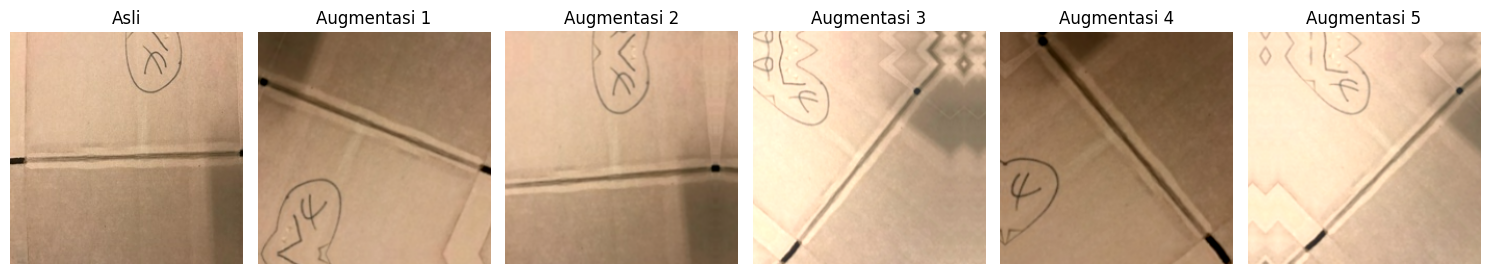

In [13]:
AUG_PARAMS = dict(rotation=0.15, zoom=0.15, translate=0.10, contrast=0.2, brightness=0.2)

def build_augmentation(seed=None):
    p = AUG_PARAMS
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical", seed=seed),
        layers.RandomRotation(p["rotation"], fill_mode="reflect", seed=seed),
        layers.RandomZoom((-p["zoom"], p["zoom"]), fill_mode="reflect", seed=seed),
        layers.RandomTranslation(p["translate"], p["translate"], fill_mode="reflect", seed=seed),
        layers.RandomContrast(p["contrast"], value_range=(0, 255), seed=seed),
        layers.RandomBrightness(p["brightness"], value_range=(0, 255), seed=seed),
    ], name="augmentation")

aug_demo = build_augmentation(seed=SPLIT_SEED)
img0 = next(iter(train_base.batch(1)))[0]
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(img0[0].numpy()); axes[0].set_title("Asli"); axes[0].axis("off")
for k in range(1, 6):
    a = aug_demo(tf.cast(img0, tf.float32), training=True)
    axes[k].imshow(np.clip(a[0].numpy(), 0, 255).astype("uint8")); axes[k].set_title(f"Augmentasi {k}"); axes[k].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "contoh_augmentasi.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Arsitektur Model
**Baseline: CNN dari nol.** Empat blok `[Conv3×3 → BN → ReLU] ×2 → MaxPool` dengan filter 32-64-128-256 dan regularisasi L2, lalu Global Average Pooling → Dropout → Dense 256 → Dropout → Softmax 6 kelas.

**Usulan: EfficientNetB0 + transfer learning.** Backbone EfficientNetB0 pra-latih ImageNet (±4 jt parameter) dengan head GAP → Dropout 0,3 → Softmax. Pelatihan dua tahap:
1. **Tahap 1 (feature extraction):** backbone dibekukan, head dilatih dengan LR 1e-3.
2. **Tahap 2 (fine-tuning):** lapisan mulai `block4a` dibuka, LR 1e-5. BatchNorm tetap beku (mode inferensi) agar statistiknya tidak rusak karena batch yang kecil.

Alasan pemilihan: EfficientNetB0 memberi akurasi tinggi dengan parameter dan FLOPs kecil, sehingga cocok untuk prototipe web/mobile dengan latensi rendah.

Kedua model dilatih dengan protokol yang sama: data, split, augmentasi, loss (*categorical cross-entropy* + label smoothing 0,1), bobot kelas, early stopping pada `val_loss`, ReduceLROnPlateau, dan 3 seed.

In [14]:
def build_baseline(cfg=BASELINE_CFG):
    reg = regularizers.l2(cfg["l2"])
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    n_blocks = len(cfg["filters"])
    for b, f in enumerate(cfg["filters"]):
        for k in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg,
                              name=f"block{b+1}_conv{k+1}")(x)
            x = layers.BatchNormalization(name=f"block{b+1}_bn{k+1}")(x)
            last = (b == n_blocks - 1 and k == 1)
            x = layers.Activation("relu", name="last_conv_act" if last else f"block{b+1}_relu{k+1}")(x)
        x = layers.MaxPooling2D(name=f"block{b+1}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(cfg["dropout"], name="dropout1")(x)
    x = layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg, name="fc")(x)
    x = layers.Dropout(cfg["dropout"], name="dropout2")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inp, out, name="baseline_cnn")


def build_proposed(cfg=PROPOSED_CFG, weights=None):
    weights = BACKBONE_WEIGHTS if weights is None else weights
    base = keras.applications.EfficientNetB0(include_top=False, weights=weights,
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = base(inp, training=False)            # BN selalu dalam mode inferensi
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(cfg["dropout"], name="head_dropout")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inp, out, name="efficientnetb0_trashnet"), base


def unfreeze_from(base, layer_name):
    names = [l.name for l in base.layers]
    start = names.index(layer_name)
    base.trainable = True
    for i, l in enumerate(base.layers):
        l.trainable = (i >= start) and not isinstance(l, layers.BatchNormalization)


def wrap_for_training(core, use_aug, seed):
    # Model pembungkus: augmentasi -> model inti. Yang disimpan nanti hanya model inti.
    if not use_aug:
        return core
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    return keras.Model(inp, core(build_augmentation(seed)(inp)), name=f"train_{core.name}")


def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    total = int(model.count_params())
    return total, trainable

_b = build_baseline(); _p, _base = build_proposed(weights=None)
print("Baseline CNN    : total %.2f M param" % (_b.count_params() / 1e6))
print("EfficientNetB0  : total %.2f M param (backbone %d layer)" % (_p.count_params() / 1e6, len(_base.layers)))
assert PROPOSED_CFG["fine_tune_at"] in [l.name for l in _base.layers]
unfreeze_from(_base, PROPOSED_CFG["fine_tune_at"])
print("Param trainable saat fine-tuning: %.2f M" % (count_params(_p)[1] / 1e6))
_b.summary(line_length=100)
del _b, _p, _base; keras.backend.clear_session()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Baseline CNN    : total 1.24 M param
EfficientNetB0  : total 4.06 M param (backbone 238 layer)
Param trainable saat fine-tuning: 3.91 M


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ rescale (Rescaling)                        │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv1 (Conv2D)                      │ (None, 224, 224, 32)            │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_bn1 (BatchNormalization)            │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_relu1 (Activation)                  │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_conv2 (Conv2D)                      │ (None, 224, 224, 32)            │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_bn2 (BatchNormalization)            │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_relu2 (Activation)                  │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block1_pool (MaxPooling2D)                 │ (None, 112, 112, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv1 (Conv2D)                      │ (None, 112, 112, 64)            │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_bn1 (BatchNormalization)            │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_relu1 (Activation)                  │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_conv2 (Conv2D)                      │ (None, 112, 112, 64)            │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_bn2 (BatchNormalization)            │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_relu2 (Activation)                  │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block2_pool (MaxPooling2D)                 │ (None, 56, 56, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_conv1 (Conv2D)                      │ (None, 56, 56, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_bn1 (BatchNormalization)            │ (None, 56, 56, 128)             │               512 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ block3_relu1 (Activation)                  │ (None, 56, 56,

 Total params: 1,242,470 (4.74 MB)

 Trainable params: 1,240,550 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Fungsi Pelatihan, Evaluasi, dan *Resume*
Setiap run disimpan di `runs/<nama_run>/` (bobot model inti, riwayat, metrik, probabilitas prediksi). Kalau `metrics.json` sudah ada, run tersebut dilewati.

Untuk model usulan, hasil **setelah Tahap 1** juga dievaluasi dan dicatat sebagai ablasi **"tanpa fine-tuning"** tanpa run tambahan.

In [15]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
                  metrics=["accuracy"])

def fit_stage(model, train_ds, epochs, lr, patience):
    compile_model(model, lr)
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=max(2, patience // 3),
                                          min_lr=1e-7, verbose=1),
    ]
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=CLASS_WEIGHT,
                  callbacks=cbs, verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    return hist

def compute_metrics(y_true, prob):
    y_pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    _, _, fc, _ = precision_recall_fscore_support(y_true, y_pred, average=None,
                                                  labels=range(NUM_CLASSES), zero_division=0)
    return dict(accuracy=float(accuracy_score(y_true, y_pred)), precision=float(p), recall=float(r),
                f1=float(f), f1_weighted=float(fw), f1_per_class={c: float(v) for c, v in zip(CLASS_NAMES, fc)})

def evaluate_core(core):
    pv = core.predict(val_ds, verbose=0); pt = core.predict(test_ds, verbose=0)
    return dict(val=compute_metrics(y_val, pv), test=compute_metrics(y_test, pt)), pv, pt

def _save_eval(run_dir, prefix, res, pv, pt):
    with open(run_dir / f"{prefix}metrics.json", "w") as f: json.dump(res, f, indent=2)
    np.save(run_dir / f"{prefix}prob_val.npy", pv); np.save(run_dir / f"{prefix}prob_test.npy", pt)

In [16]:
def run_experiment(name, model_type, seed, use_aug=True):
    run_dir = RUNS_DIR / name
    if (run_dir / "metrics.json").exists():
        print(f"[SKIP] {name} sudah selesai — memuat hasil.")
        return json.load(open(run_dir / "metrics.json"))
    run_dir.mkdir(parents=True, exist_ok=True)
    keras.backend.clear_session(); set_seed(seed)
    train_ds = make_train_ds(seed)
    t0 = time.time()
    print(f"\n{'='*80}\nRUN {name} | model={model_type} | seed={seed} | augmentasi={use_aug}\n{'='*80}")

    if model_type == "baseline":
        core = build_baseline()
        trainer = wrap_for_training(core, use_aug, seed)
        c = BASELINE_CFG
        hist = fit_stage(trainer, train_ds, c["epochs"], c["lr"], c["patience"])
        hist["stage1_epochs"] = len(hist["loss"])
    else:
        core, base = build_proposed()
        trainer = wrap_for_training(core, use_aug, seed)
        c = PROPOSED_CFG
        print("--- Tahap 1: feature extraction (backbone beku) ---")
        h1 = fit_stage(trainer, train_ds, c["stage1_epochs"], c["stage1_lr"], c["stage1_patience"])
        # Ablasi "tanpa fine-tuning": evaluasi model setelah Tahap 1
        res1, pv1, pt1 = evaluate_core(core)
        _save_eval(run_dir, "stage1_", res1, pv1, pt1)
        print(f"Tahap 1 -> val F1={res1['val']['f1']:.4f} | test F1={res1['test']['f1']:.4f}")
        print("--- Tahap 2: fine-tuning ---")
        unfreeze_from(base, c["fine_tune_at"])
        h2 = fit_stage(trainer, train_ds, c["stage2_epochs"], c["stage2_lr"], c["stage2_patience"])
        hist = {k: h1[k] + h2[k] for k in h1 if isinstance(h1[k], list) and k in h2}
        hist["stage1_epochs"] = len(h1["loss"])
        hist["best_epoch"] = hist["stage1_epochs"] + h2["best_epoch"]

    train_time = time.time() - t0
    res, pv, pt = evaluate_core(core)
    res.update(name=name, model_type=model_type, seed=seed, use_aug=use_aug,
               epochs_run=len(hist["loss"]), train_time_s=train_time)
    core.save_weights(run_dir / "core.weights.h5")
    with open(run_dir / "history.json", "w") as f: json.dump(hist, f)
    _save_eval(run_dir, "", res, pv, pt)
    print(f"Selesai {name}: val F1={res['val']['f1']:.4f} | test acc={res['test']['accuracy']:.4f} "
          f"| test F1={res['test']['f1']:.4f} | {train_time/60:.1f} menit")
    return res

## 7. Menjalankan Eksperimen
| Konfigurasi | Keterangan | Run |
|---|---|---|
| `baseline_cnn` | CNN dari nol + augmentasi | 3 seed |
| `efficientnetb0` | **Model usulan**: transfer learning + fine-tuning + augmentasi | 3 seed |
| `efficientnetb0` (tahap 1) | Ablasi: **tanpa fine-tuning** (diambil dari run di atas) | — |
| `efficientnetb0_noaug` | Ablasi: **tanpa augmentasi** | 3 seed |

Run utama dijalankan lebih dulu, lalu run ablasi. Jika Colab terputus, jalankan ulang semua sel dari atas; run yang sudah selesai akan dilewati.

In [17]:
EXPERIMENTS = []
for s in SEEDS:
    EXPERIMENTS.append((f"baseline_cnn_s{s}", "baseline", s, True))
    EXPERIMENTS.append((f"efficientnetb0_s{s}", "proposed", s, True))
for s in SEEDS:
    EXPERIMENTS.append((f"efficientnetb0_noaug_s{s}", "proposed", s, False))

ALL_RESULTS = {}
for name, mtype, seed, aug in EXPERIMENTS:
    ALL_RESULTS[name] = run_experiment(name, mtype, seed, use_aug=aug)
print("\nSemua eksperimen selesai.")


RUN baseline_cnn_s42 | model=baseline | seed=42 | augmentasi=True
Epoch 1/80
56/56 - 32s - 566ms/step - accuracy: 0.3248 - loss: 1.8146 - val_accuracy: 0.2328 - val_loss: 1.9756 - learning_rate: 0.0010
Epoch 2/80
56/56 - 16s - 285ms/step - accuracy: 0.3730 - loss: 1.6870 - val_accuracy: 0.0608 - val_loss: 2.0569 - learning_rate: 0.0010
Epoch 3/80
56/56 - 16s - 287ms/step - accuracy: 0.4127 - loss: 1.6350 - val_accuracy: 0.1561 - val_loss: 2.0415 - learning_rate: 0.0010
Epoch 4/80
56/56 - 16s - 290ms/step - accuracy: 0.4002 - loss: 1.6162 - val_accuracy: 0.2646 - val_loss: 2.1200 - learning_rate: 0.0010
Epoch 5/80

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
56/56 - 16s - 293ms/step - accuracy: 0.4246 - loss: 1.6109 - val_accuracy: 0.1720 - val_loss: 2.1146 - learning_rate: 0.0010
Epoch 6/80
56/56 - 17s - 296ms/step - accuracy: 0.4705 - loss: 1.5469 - val_accuracy: 0.1799 - val_loss: 2.0775 - learning_rate: 3.0000e-04
Epoch 7/80
56/56 - 17s - 299ms/step 

E0000 00:00:1794911265.042926      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/train_efficientnetb0_trashnet_1/efficientnetb0_trashnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


56/56 - 19s - 339ms/step - accuracy: 0.5119 - loss: 1.3987 - val_accuracy: 0.7037 - val_loss: 1.0132 - learning_rate: 0.0010
Epoch 2/20
56/56 - 5s - 95ms/step - accuracy: 0.7404 - loss: 1.0186 - val_accuracy: 0.7487 - val_loss: 0.9043 - learning_rate: 0.0010
Epoch 3/20
56/56 - 5s - 95ms/step - accuracy: 0.7630 - loss: 0.9150 - val_accuracy: 0.8095 - val_loss: 0.8371 - learning_rate: 0.0010
Epoch 4/20
56/56 - 5s - 95ms/step - accuracy: 0.7925 - loss: 0.8640 - val_accuracy: 0.8280 - val_loss: 0.8314 - learning_rate: 0.0010
Epoch 5/20
56/56 - 5s - 97ms/step - accuracy: 0.8197 - loss: 0.8272 - val_accuracy: 0.8439 - val_loss: 0.7984 - learning_rate: 0.0010
Epoch 6/20
56/56 - 5s - 96ms/step - accuracy: 0.8362 - loss: 0.8115 - val_accuracy: 0.8545 - val_loss: 0.7948 - learning_rate: 0.0010
Epoch 7/20
56/56 - 5s - 96ms/step - accuracy: 0.8469 - loss: 0.7822 - val_accuracy: 0.8545 - val_loss: 0.7792 - learning_rate: 0.0010
Epoch 8/20
56/56 - 5s - 95ms/step - accuracy: 0.8577 - loss: 0.7713 - v

E0000 00:00:1794911382.755439      87 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794911382.937794      87 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794911383.897308      87 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794911384.063144      87 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794911395.068626      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

Tahap 1 -> val F1=0.8413 | test F1=0.8208
--- Tahap 2: fine-tuning ---
Epoch 1/40


E0000 00:00:1794911426.961597      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/train_efficientnetb0_trashnet_1/efficientnetb0_trashnet_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


... (9 outputs left out)

E0000 00:00:1794914955.816192      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794914955.983179      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794914957.919276      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794914958.104942      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


56/56 - 48s - 855ms/step - accuracy: 0.5765 - loss: 1.2912 - val_accuracy: 0.7513 - val_loss: 0.9568 - learning_rate: 0.0010
Epoch 2/20
56/56 - 3s - 46ms/step - accuracy: 0.7982 - loss: 0.8878 - val_accuracy: 0.8095 - val_loss: 0.8605 - learning_rate: 0.0010
Epoch 3/20
56/56 - 2s - 45ms/step - accuracy: 0.8401 - loss: 0.8010 - val_accuracy: 0.8413 - val_loss: 0.8122 - learning_rate: 0.0010
Epoch 4/20
56/56 - 3s - 45ms/step - accuracy: 0.8622 - loss: 0.7414 - val_accuracy: 0.8624 - val_loss: 0.7751 - learning_rate: 0.0010
Epoch 5/20
56/56 - 2s - 45ms/step - accuracy: 0.8895 - loss: 0.7078 - val_accuracy: 0.8783 - val_loss: 0.7576 - learning_rate: 0.0010
Epoch 6/20
56/56 - 3s - 45ms/step - accuracy: 0.8821 - loss: 0.6964 - val_accuracy: 0.8677 - val_loss: 0.7501 - learning_rate: 0.0010
Epoch 7/20
56/56 - 2s - 45ms/step - accuracy: 0.9031 - loss: 0.6748 - val_accuracy: 0.8836 - val_loss: 0.7360 - learning_rate: 0.0010
Epoch 8/20
56/56 - 3s - 45ms/step - accuracy: 0.9161 - loss: 0.6575 - v

E0000 00:00:1794915065.800302      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794915068.427376      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794915068.606765      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794915069.531350      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794915071.052425      86 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

56/56 - 81s - 1s/step - accuracy: 0.9603 - loss: 0.5720 - val_accuracy: 0.9101 - val_loss: 0.6718 - learning_rate: 1.0000e-05
Epoch 2/40
56/56 - 4s - 77ms/step - accuracy: 0.9683 - loss: 0.5573 - val_accuracy: 0.9127 - val_loss: 0.6690 - learning_rate: 1.0000e-05
Epoch 3/40
56/56 - 4s - 76ms/step - accuracy: 0.9666 - loss: 0.5554 - val_accuracy: 0.9048 - val_loss: 0.6642 - learning_rate: 1.0000e-05
Epoch 4/40
56/56 - 4s - 77ms/step - accuracy: 0.9785 - loss: 0.5398 - val_accuracy: 0.9127 - val_loss: 0.6562 - learning_rate: 1.0000e-05
Epoch 5/40
56/56 - 4s - 77ms/step - accuracy: 0.9773 - loss: 0.5353 - val_accuracy: 0.9153 - val_loss: 0.6547 - learning_rate: 1.0000e-05
Epoch 6/40
56/56 - 4s - 78ms/step - accuracy: 0.9847 - loss: 0.5246 - val_accuracy: 0.9206 - val_loss: 0.6480 - learning_rate: 1.0000e-05
Epoch 7/40
56/56 - 4s - 76ms/step - accuracy: 0.9847 - loss: 0.5239 - val_accuracy: 0.9127 - val_loss: 0.6490 - learning_rate: 1.0000e-05
Epoch 8/40
56/56 - 4s - 78ms/step - accuracy: 

## 8. Hasil dan Perbandingan Model
### 8.1 Rekap per run dan rerata ± simpangan baku (3 seed)
Semua angka di bawah dihitung pada **data uji yang sama**. Pemilihan model terbaik per konfigurasi memakai **F1 validasi**, bukan F1 uji, agar data uji tidak ikut memengaruhi pemilihan model.

In [18]:
VARIANT_LABEL = {
    "baseline_cnn":          "Baseline CNN",
    "efficientnetb0":        "EfficientNetB0 (usulan)",
    "efficientnetb0_stage1": "Usulan tanpa fine-tuning",
    "efficientnetb0_noaug":  "Usulan tanpa augmentasi",
}

rows = []
for name, mtype, seed, aug in EXPERIMENTS:
    run_dir = RUNS_DIR / name
    variant = name.rsplit("_s", 1)[0]
    entries = [(variant, json.load(open(run_dir / "metrics.json")))]
    if variant == "efficientnetb0":
        entries.append(("efficientnetb0_stage1", json.load(open(run_dir / "stage1_metrics.json"))))
    for v, m in entries:
        rows.append(dict(variant=v, model=VARIANT_LABEL[v], seed=seed, run=name,
                         val_f1=m["val"]["f1"], **{f"test_{k}": m["test"][k] for k in
                         ["accuracy", "precision", "recall", "f1", "f1_weighted"]},
                         epochs=m.get("epochs_run", np.nan), train_min=m.get("train_time_s", np.nan) / 60))
runs_df = pd.DataFrame(rows)
runs_df.to_csv(TAB_DIR / "hasil_per_run.csv", index=False)
display(runs_df.round(4))

def mean_std(s):
    return f"{s.mean():.4f} ± {s.std(ddof=1):.4f}" if len(s) > 1 else f"{s.mean():.4f}"

metric_cols = ["test_accuracy", "test_precision", "test_recall", "test_f1"]
summary = runs_df.groupby("variant", sort=False)[metric_cols].agg(mean_std)
summary.index = summary.index.map(VARIANT_LABEL)
summary.columns = ["Acc.", "Prec. (macro)", "Rec. (macro)", "F1 (macro)"]
summary

,variant,model,seed,run,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_f1_weighted,epochs,train_min
0,baseline_cnn,Baseline CNN,42,baseline_cnn_s42,0.6977,0.6966,0.6830,0.7223,0.6808,0.7049,43.0,12.1168
1,efficientnetb0,EfficientNetB0 (usulan),42,efficientnetb0_s42,0.9195,0.8997,0.8853,0.8821,0.8822,0.9000,48.0,6.9297
2,efficientnetb0_stage1,Usulan tanpa fine-tuning,42,efficientnetb0_s42,0.8413,0.8496,0.8168,0.8340,0.8208,0.8529,NaN,NaN
3,baseline_cnn,Baseline CNN,123,baseline_cnn_s123,0.6833,0.7018,0.6868,0.7275,0.6926,0.7067,55.0,15.3173
4,efficientnetb0,EfficientNetB0 (usulan),123,efficientnetb0_s123,0.8940,0.8971,0.8770,0.8911,0.8825,0.8979,58.0,8.1641
5,efficientnetb0_stage1,Usulan tanpa fine-tuning,123,efficientnetb0_s123,0.8480,0.8496,0.8208,0.8443,0.8257,0.8540,NaN,NaN
6,baseline_cnn,Baseline CNN,2024,baseline_cnn_s2024,0.6606,0.7071,0.6940,0.7375,0.6952,0.7121,80.0,22.2341
7,efficientnetb0,EfficientNetB0 (usulan),2024,efficientnetb0_s2024,0.9128,0.9103,0.9008,0.8970,0.8977,0.9106,60.0,8.3298
8,efficientnetb0_stage1,Usulan tanpa fine-tuning,2024,efficientnetb0_s2024,0.8513,0.8549,0.8256,0.8376,0.8287,0.8569,NaN,NaN
9,efficientnetb0_noaug,Usulan tanpa augmentasi,42,efficientnetb0_noaug_s42,0.9188,0.9129,0.9058,0.8858,0.8938,0.9126,60.0,6.0268


,Acc.,Prec. (macro),Rec. (macro),F1 (macro)
variant,,,,
Baseline CNN,0.7018 ± 0.0053,0.6879 ± 0.0056,0.7291 ± 0.0077,0.6895 ± 0.0077
EfficientNetB0 (usulan),0.9024 ± 0.0070,0.8877 ± 0.0121,0.8901 ± 0.0075,0.8875 ± 0.0089
Usulan tanpa fine-tuning,0.8514 ± 0.0030,0.8211 ± 0.0044,0.8386 ± 0.0053,0.8251 ± 0.0040
Usulan tanpa augmentasi,0.9085 ± 0.0055,0.8984 ± 0.0091,0.8862 ± 0.0036,0.8908 ± 0.0056


### 8.2 Jumlah parameter dan waktu inferensi
Waktu inferensi diukur per gambar (batch = 1). Ada 10 iterasi pemanasan, lalu nilai yang dilaporkan adalah median dari 100 iterasi. Pengukuran dilakukan di GPU (jika ada) dan di CPU, karena prototipe sering di-*deploy* di server tanpa GPU.

In [19]:
def best_run(variant):
    sub = runs_df[runs_df["variant"] == variant]
    return sub.loc[sub["val_f1"].idxmax()]

def load_core(variant, run_name):
    keras.backend.clear_session()
    if variant.startswith("baseline"):
        core = build_baseline()
    else:
        # PENTING: struktur harus sama dengan saat training. Keras menambah lapisan Rescaling(1/std)
        # hanya jika weights="imagenet"; weights=None akan membuat arsitektur berbeda.
        core, _ = build_proposed(weights=BACKBONE_WEIGHTS)
    core.load_weights(RUNS_DIR / run_name / "core.weights.h5")
    return core

def time_inference(model, device, n_warmup=10, n_runs=100):
    x = tf.random.uniform((1, IMG_SIZE, IMG_SIZE, 3), 0, 255)
    with tf.device(device):
        f = tf.function(lambda t: model(t, training=False))
        for _ in range(n_warmup): f(x).numpy()
        ts = []
        for _ in range(n_runs):
            t0 = time.perf_counter(); f(x).numpy(); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

best = {v: best_run(v) for v in ["baseline_cnn", "efficientnetb0"]}
eff_rows = {}
for v, r in best.items():
    core = load_core(v, r["run"])
    total, _ = count_params(core)
    gpu_ms = time_inference(core, "/GPU:0") if gpus else np.nan
    cpu_ms = time_inference(core, "/CPU:0")
    eff_rows[VARIANT_LABEL[v]] = {"Param (M)": total / 1e6, "Inferensi GPU (ms)": gpu_ms, "Inferensi CPU (ms)": cpu_ms}
    print(f"{VARIANT_LABEL[v]:<26} param={total/1e6:.2f}M | GPU={gpu_ms:.2f} ms | CPU={cpu_ms:.2f} ms | run terbaik={r['run']}")
eff_df = pd.DataFrame(eff_rows).T

Baseline CNN               param=1.24M | GPU=3.99 ms | CPU=43.86 ms | run terbaik=baseline_cnn_s42
EfficientNetB0 (usulan)    param=4.06M | GPU=9.66 ms | CPU=52.00 ms | run terbaik=efficientnetb0_s42


In [20]:
table4 = summary.loc[["Baseline CNN", "EfficientNetB0 (usulan)"]].join(eff_df.round(2))
table4.index.name = "Model"
table4.to_csv(TAB_DIR / "tabel4_perbandingan_model.csv")

b_f1 = runs_df.query("variant=='baseline_cnn'")["test_f1"].mean()
p_f1 = runs_df.query("variant=='efficientnetb0'")["test_f1"].mean()
print("Tabel 4. Perbandingan kinerja model pada data uji (rerata ± std, 3 seed)")
display(table4)
print(f"Peningkatan F1 macro usulan vs baseline: {p_f1 - b_f1:+.4f} poin "
      f"({(p_f1 - b_f1) / b_f1 * 100:+.1f}% relatif)")

Tabel 4. Perbandingan kinerja model pada data uji (rerata ± std, 3 seed)


,Acc.,Prec. (macro),Rec. (macro),F1 (macro),Param (M),Inferensi GPU (ms),Inferensi CPU (ms)
Model,,,,,,,
Baseline CNN,0.7018 ± 0.0053,0.6879 ± 0.0056,0.7291 ± 0.0077,0.6895 ± 0.0077,1.24,3.99,43.86
EfficientNetB0 (usulan),0.9024 ± 0.0070,0.8877 ± 0.0121,0.8901 ± 0.0075,0.8875 ± 0.0089,4.06,9.66,52.00


Peningkatan F1 macro usulan vs baseline: +0.1979 poin (+28.7% relatif)


### 8.3 Uji signifikansi McNemar
Uji ini membandingkan prediksi model terbaik baseline dan model terbaik usulan pada data uji yang sama (uji binomial eksak terhadap pasangan prediksi yang berbeda benar/salahnya). Jika p < 0,05, perbedaan kinerja kedua model signifikan secara statistik.

In [21]:
pred_b = np.load(RUNS_DIR / best["baseline_cnn"]["run"] / "prob_test.npy").argmax(1)
pred_p = np.load(RUNS_DIR / best["efficientnetb0"]["run"] / "prob_test.npy").argmax(1)
cb, cp = pred_b == y_test, pred_p == y_test
n01 = int(np.sum(cb & ~cp))   # baseline benar, usulan salah
n10 = int(np.sum(~cb & cp))   # baseline salah, usulan benar
p_val = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
print(f"Baseline benar & usulan salah : {n01}")
print(f"Baseline salah & usulan benar : {n10}")
print(f"p-value McNemar (eksak)       : {p_val:.3e}  ->", "signifikan" if p_val < 0.05 else "tidak signifikan", "(α = 0,05)")

Baseline benar & usulan salah : 18
Baseline salah & usulan benar : 95
p-value McNemar (eksak)       : 7.970e-14  -> signifikan (α = 0,05)


### 8.4 Studi ablasi (komponen model usulan)

In [22]:
abl = runs_df[runs_df["variant"].str.startswith("efficientnetb0")]
abl_tab = abl.groupby("variant", sort=False)[metric_cols].agg(mean_std)
abl_tab.index = abl_tab.index.map(VARIANT_LABEL)
abl_tab.columns = summary.columns
full_f1 = abl.query("variant=='efficientnetb0'")["test_f1"].mean()
abl_tab["ΔF1 vs usulan"] = [f"{abl.query('variant==@v')['test_f1'].mean() - full_f1:+.4f}"
                            for v in abl["variant"].unique()]
abl_tab.index.name = "Konfigurasi"
abl_tab.to_csv(TAB_DIR / "tabel_ablasi.csv")
abl_tab

,Acc.,Prec. (macro),Rec. (macro),F1 (macro),ΔF1 vs usulan
Konfigurasi,,,,,
EfficientNetB0 (usulan),0.9024 ± 0.0070,0.8877 ± 0.0121,0.8901 ± 0.0075,0.8875 ± 0.0089,+0.0000
Usulan tanpa fine-tuning,0.8514 ± 0.0030,0.8211 ± 0.0044,0.8386 ± 0.0053,0.8251 ± 0.0040,-0.0624
Usulan tanpa augmentasi,0.9085 ± 0.0055,0.8984 ± 0.0091,0.8862 ± 0.0036,0.8908 ± 0.0056,+0.0034


### 8.5 Kurva pelatihan (run terbaik tiap model)

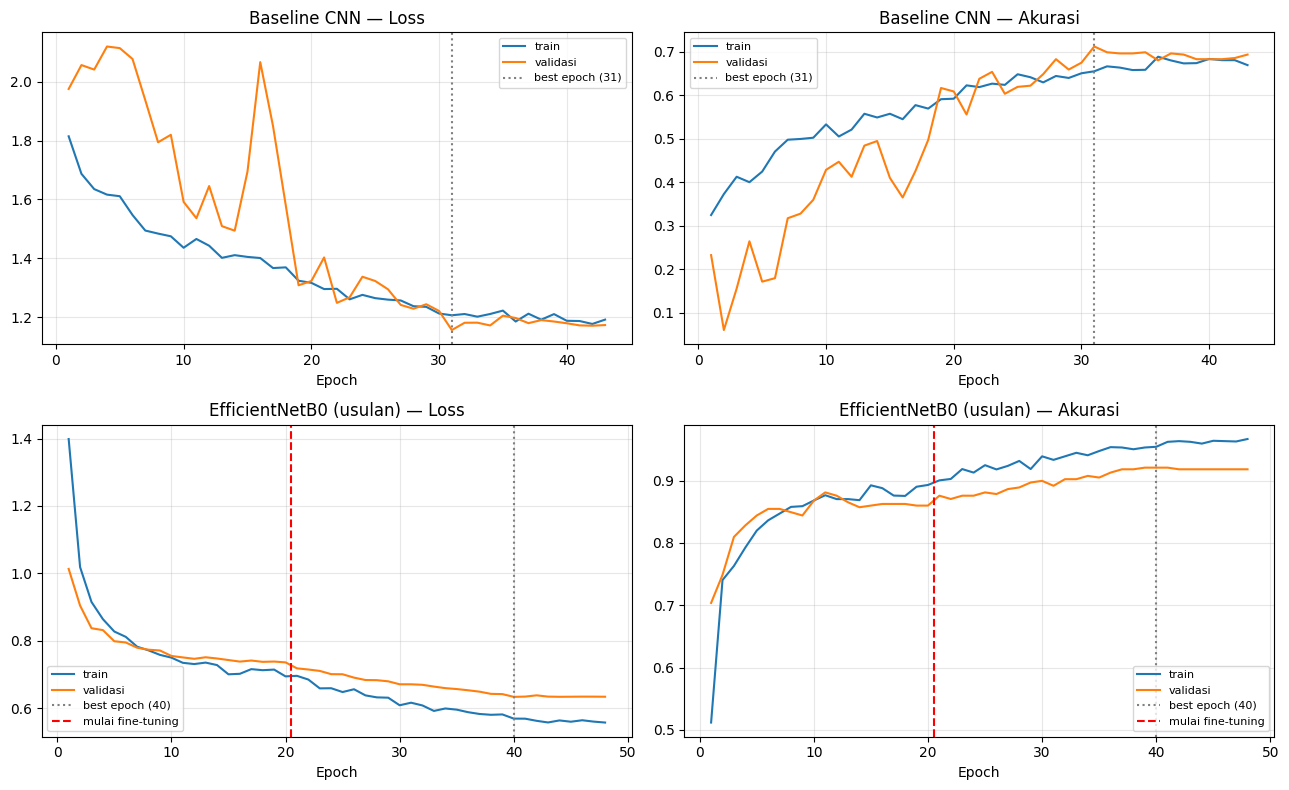

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, v in enumerate(["baseline_cnn", "efficientnetb0"]):
    h = json.load(open(RUNS_DIR / best[v]["run"] / "history.json"))
    ep = np.arange(1, len(h["loss"]) + 1)
    for col, (key, title) in enumerate([("loss", "Loss"), ("accuracy", "Akurasi")]):
        ax = axes[row, col]
        ax.plot(ep, h[key], label="train"); ax.plot(ep, h[f"val_{key}"], label="validasi")
        ax.axvline(h["best_epoch"], color="gray", ls=":", label=f"best epoch ({h['best_epoch']})")
        if v == "efficientnetb0":
            ax.axvline(h["stage1_epochs"] + 0.5, color="red", ls="--", label="mulai fine-tuning")
        ax.set_title(f"{VARIANT_LABEL[v]} — {title}"); ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "gambar4_kurva_pelatihan.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Analisis Galat dan Explainability
### 9.1 Confusion matrix dan laporan per kelas (run terbaik)


Baseline CNN (baseline_cnn_s42)
              precision    recall  f1-score   support

   cardboard     0.8983    0.8689    0.8833        61
       glass     0.6324    0.5733    0.6014        75
       metal     0.6429    0.5806    0.6102        62
       paper     0.8125    0.7303    0.7692        89
     plastic     0.7656    0.6806    0.7206        72
       trash     0.3462    0.9000    0.5000        20

    accuracy                         0.6966       379
   macro avg     0.6830    0.7223    0.6808       379
weighted avg     0.7294    0.6966    0.7049       379


EfficientNetB0 (usulan) (efficientnetb0_s42)
              precision    recall  f1-score   support

   cardboard     0.9492    0.9180    0.9333        61
       glass     0.9306    0.8933    0.9116        75
       metal     0.8310    0.9516    0.8872        62
       paper     0.8830    0.9326    0.9071        89
     plastic     0.9683    0.8472    0.9037        72
       trash     0.7500    0.7500    0.7500        20

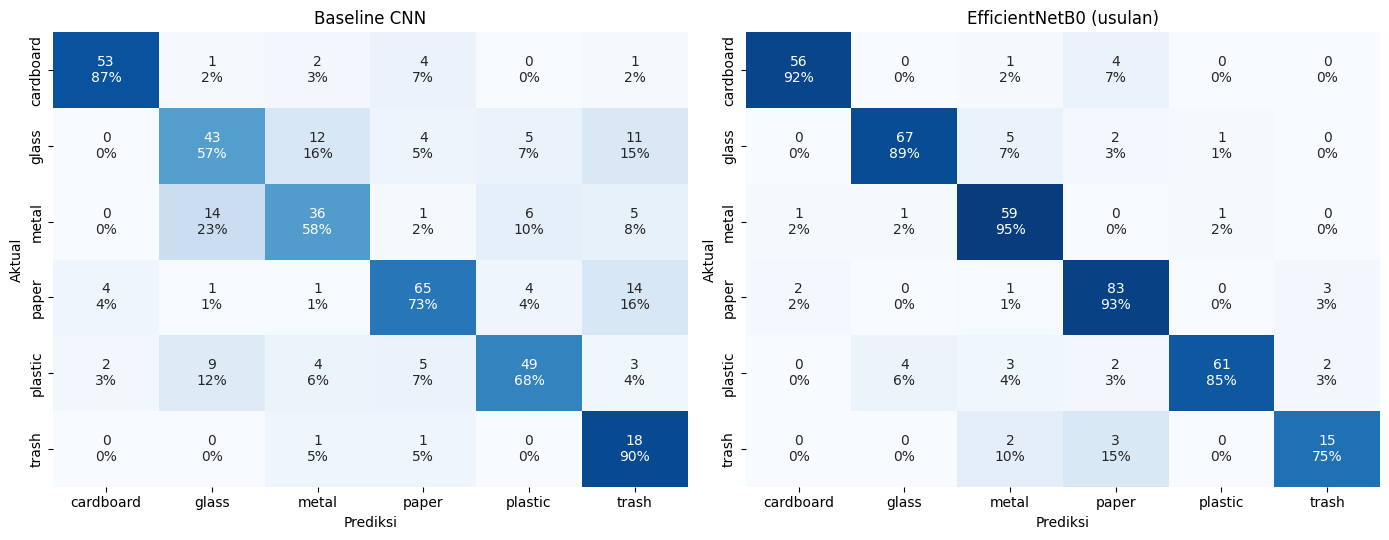

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, v in zip(axes, ["baseline_cnn", "efficientnetb0"]):
    pred = np.load(RUNS_DIR / best[v]["run"] / "prob_test.npy").argmax(1)
    cm = confusion_matrix(y_test, pred, labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True)
    annot = np.array([[f"{cm[i,j]}\n{cmn[i,j]:.0%}" for j in range(NUM_CLASSES)] for i in range(NUM_CLASSES)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(VARIANT_LABEL[v])
    print(f"\n{VARIANT_LABEL[v]} ({best[v]['run']})")
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

In [25]:
# Pasangan kelas yang paling sering tertukar (model usulan)
prob_p = np.load(RUNS_DIR / best["efficientnetb0"]["run"] / "prob_test.npy")
pred_p = prob_p.argmax(1)
cm_p = confusion_matrix(y_test, pred_p, labels=range(NUM_CLASSES))
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm_p[i, j])) for i in range(NUM_CLASSES)
         for j in range(NUM_CLASSES) if i != j and cm_p[i, j] > 0]
confused = pd.DataFrame(pairs, columns=["Aktual", "Diprediksi", "Jumlah"]).sort_values("Jumlah", ascending=False)
print(f"Total salah prediksi model usulan: {(pred_p != y_test).sum()} dari {len(y_test)}")
confused.head(8)

Total salah prediksi model usulan: 38 dari 379


,Aktual,Diprediksi,Jumlah
2,glass,metal,5
11,plastic,glass,4
1,cardboard,paper,4
16,trash,paper,3
10,paper,trash,3
12,plastic,metal,3
14,plastic,trash,2
3,glass,paper,2


### 9.2 Contoh salah prediksi model usulan (diurutkan dari keyakinan tertinggi)

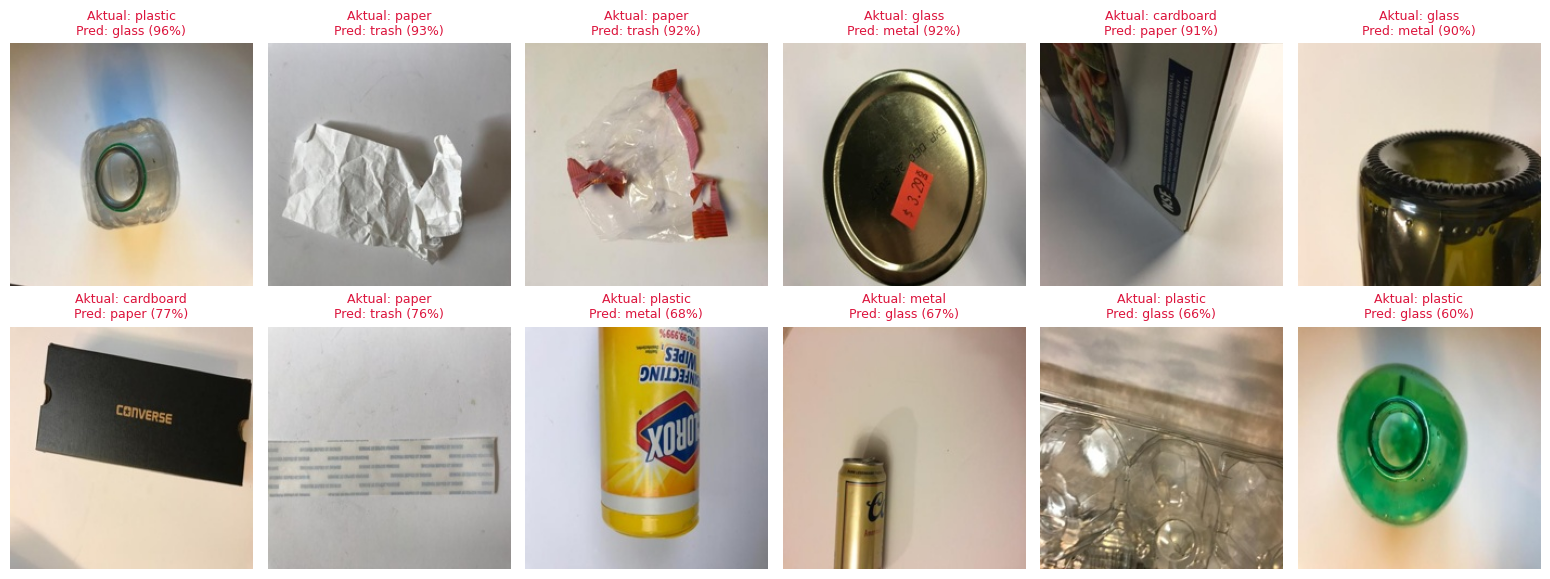

In [26]:
wrong = np.where(pred_p != y_test)[0]
wrong = wrong[np.argsort(-prob_p[wrong].max(1))][:12]
if len(wrong):
    ncol = 6; nrow = math.ceil(len(wrong) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.6, nrow * 3), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(Image.open(test_df.loc[i, "filepath"]))
        ax.set_title(f"Aktual: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[pred_p[i]]} ({prob_p[i].max():.0%})",
                     fontsize=9, color="crimson")
    plt.tight_layout(); plt.savefig(FIG_DIR / "contoh_salah_prediksi.png", dpi=150, bbox_inches="tight"); plt.show()

### 9.3 Grad-CAM
Grad-CAM menunjukkan bagian gambar yang paling memengaruhi keputusan model. Untuk baseline dipakai lapisan `last_conv_act`, untuk model usulan keluaran terakhir backbone EfficientNetB0 (`top_activation`). Jika model fokus ke objek sampah dan bukan ke latar belakang, keputusannya lebih bisa dipercaya.

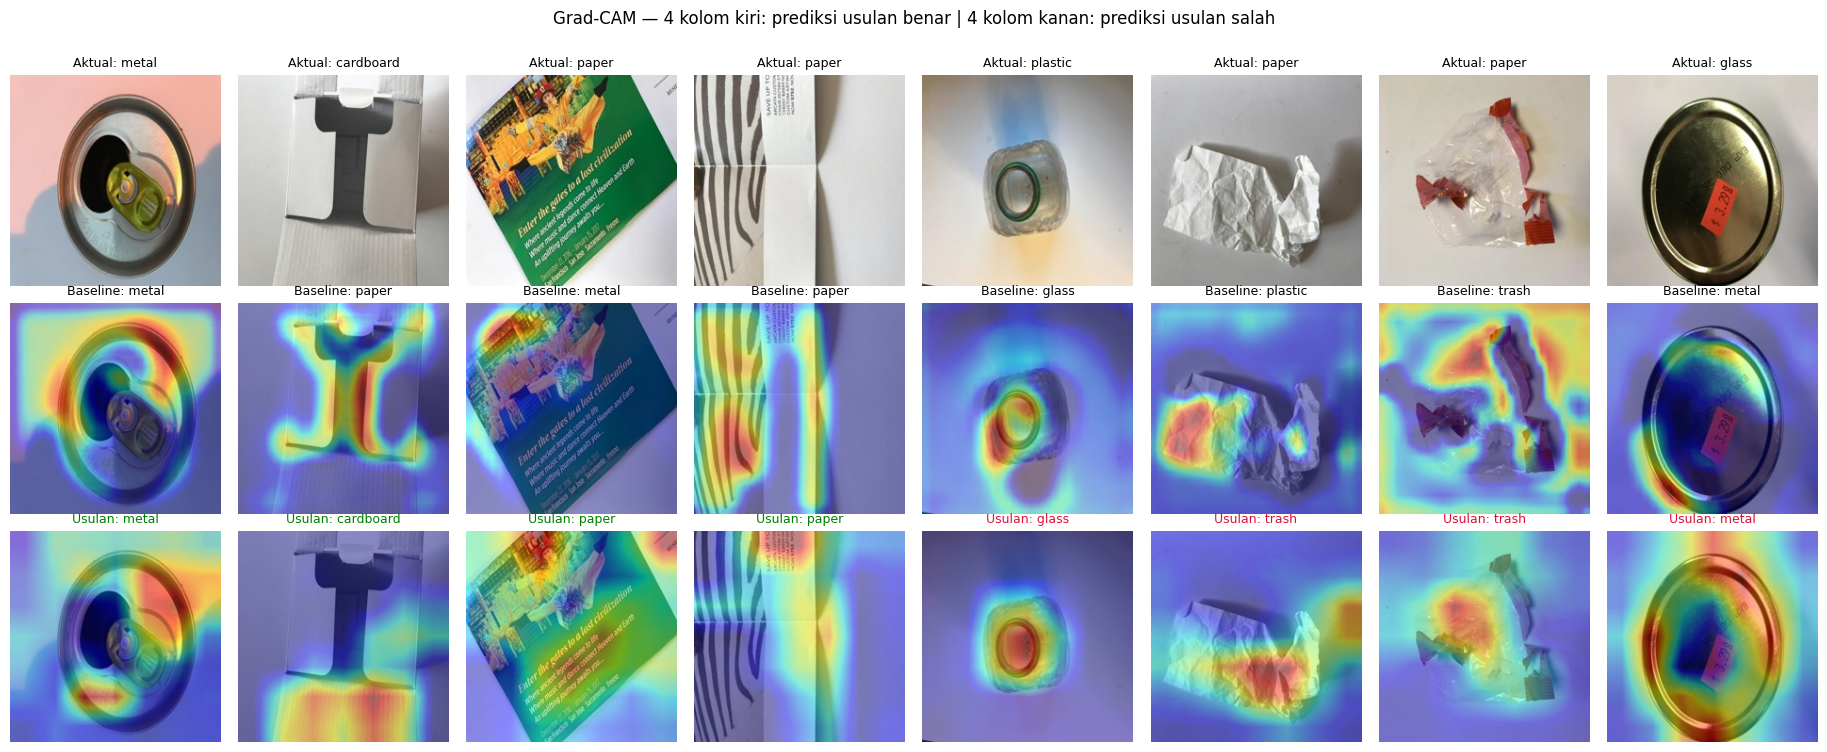

In [27]:
def gradcam(core, img_batch, model_type, class_idx=None):
    img_batch = tf.convert_to_tensor(img_batch, tf.float32)
    if model_type == "baseline":
        gm = keras.Model(core.inputs, [core.get_layer("last_conv_act").output, core.output])
        with tf.GradientTape() as tape:
            conv, preds = gm(img_batch, training=False)
            idx = tf.argmax(preds, 1) if class_idx is None else tf.constant(class_idx)
            score = tf.gather(preds, idx, axis=1, batch_dims=1)
    else:
        base = core.get_layer("efficientnetb0")
        head = [core.get_layer("gap"), core.get_layer("head_dropout"), core.get_layer("predictions")]
        with tf.GradientTape() as tape:
            conv = base(img_batch, training=False)
            tape.watch(conv)
            x = conv
            for l in head: x = l(x, training=False)
            preds = x
            idx = tf.argmax(preds, 1) if class_idx is None else tf.constant(class_idx)
            score = tf.gather(preds, idx, axis=1, batch_dims=1)
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(conv * w, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    return cam, preds.numpy()

def overlay(img, cam, alpha=0.45):
    heat = plt.cm.jet(cam)[..., :3] * 255
    return np.clip((1 - alpha) * img + alpha * heat, 0, 255).astype("uint8")

# 4 contoh benar (satu per kelas acak) + 4 contoh salah dari model usulan
rng = np.random.default_rng(SPLIT_SEED)
correct_idx = rng.choice(np.where(pred_p == y_test)[0], 4, replace=False)
sel = list(correct_idx) + list(wrong[:4])
imgs = np.stack([np.array(Image.open(test_df.loc[i, "filepath"]).convert("RGB")) for i in sel]).astype("float32")

core_b = load_core("baseline_cnn", best["baseline_cnn"]["run"])
cam_b, pb = gradcam(core_b, imgs, "baseline")
core_p = load_core("efficientnetb0", best["efficientnetb0"]["run"])
cam_p, pp = gradcam(core_p, imgs, "proposed")

fig, axes = plt.subplots(3, len(sel), figsize=(len(sel) * 2.3, 7.4))
for k, i in enumerate(sel):
    axes[0, k].imshow(imgs[k].astype("uint8")); axes[0, k].set_title(f"Aktual: {CLASS_NAMES[y_test[i]]}", fontsize=9)
    axes[1, k].imshow(overlay(imgs[k], cam_b[k])); axes[1, k].set_title(f"Baseline: {CLASS_NAMES[pb[k].argmax()]}", fontsize=9)
    axes[2, k].imshow(overlay(imgs[k], cam_p[k]))
    axes[2, k].set_title(f"Usulan: {CLASS_NAMES[pp[k].argmax()]}", fontsize=9,
                         color="green" if pp[k].argmax() == y_test[i] else "crimson")
    for r in range(3): axes[r, k].axis("off")
plt.suptitle("Grad-CAM — 4 kolom kiri: prediksi usulan benar | 4 kolom kanan: prediksi usulan salah", y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Menyimpan Model (.h5)
Model inti dari run terbaik masing-masing konfigurasi (dipilih berdasarkan F1 validasi) disimpan dalam format **.h5**. Metadata yang dibutuhkan prototipe juga disimpan: urutan nama kelas, ukuran input, dan cara pra-pemrosesan.

Setelah itu model dimuat ulang dan prediksinya dibandingkan dengan model di memori, untuk memastikan file `.h5` dapat dipakai di prototipe (Streamlit/FastAPI).

In [28]:
def load_h5_model(path):
    # Memuat model .h5 dengan benar.
    # Keras (format .h5 lama) tidak menghitung ulang konstanta mean/variance pada lapisan Normalization
    # milik EfficientNet saat memuat file -> prediksi jadi salah (mean=0, var=1). finalize_state() memperbaikinya.
    # Wajib dipanggil SEBELUM predict pertama. Jangan lupa di prototipe (Streamlit/FastAPI).
    m = keras.models.load_model(path, compile=False)
    for l in m._flatten_layers(include_self=True, recursive=True):
        if isinstance(l, layers.Normalization):
            l.finalize_state()
    return m

final_paths = {}
for v, fname in [("baseline_cnn", "baseline_cnn_trashnet.h5"), ("efficientnetb0", "efficientnetb0_trashnet.h5")]:
    core = load_core(v, best[v]["run"])
    path = MODEL_DIR / fname
    core.save(path)
    core.save(path.with_suffix(".keras"))   # format native Keras (cadangan; tidak butuh load_h5_model)
    final_paths[v] = path
    print(f"Disimpan: {path}  ({path.stat().st_size / 1e6:.1f} MB)  <- {best[v]['run']}")

model_info = dict(
    class_names=CLASS_NAMES,
    input_size=[IMG_SIZE, IMG_SIZE, 3],
    preprocessing="RGB, exif_transpose, resize 224x224 bicubic, piksel float32 0-255 TANPA normalisasi "
                  "(normalisasi sudah di dalam model)",
    models={v: dict(file=final_paths[v].name, source_run=best[v]["run"],
                    test_accuracy=float(best[v]["test_accuracy"]), test_f1_macro=float(best[v]["test_f1"]))
            for v in final_paths},
    dataset=HF_DATASET, split_seed=SPLIT_SEED, seeds=SEEDS,
    tf_version=tf.__version__, keras_version=keras.__version__,
)
with open(MODEL_DIR / "model_info.json", "w") as f: json.dump(model_info, f, indent=2)
with open(MODEL_DIR / "class_names.json", "w") as f: json.dump(CLASS_NAMES, f)
print(json.dumps(model_info, indent=2))

Disimpan: outputs/models/baseline_cnn_trashnet.h5  (5.1 MB)  <- baseline_cnn_s42


Disimpan: outputs/models/efficientnetb0_trashnet.h5  (16.7 MB)  <- efficientnetb0_s42
{
  "class_names": [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
  ],
  "input_size": [
    224,
    224,
    3
  ],
  "preprocessing": "RGB, exif_transpose, resize 224x224 bicubic, piksel float32 0-255 TANPA normalisasi (normalisasi sudah di dalam model)",
  "models": {
    "baseline_cnn": {
      "file": "baseline_cnn_trashnet.h5",
      "source_run": "baseline_cnn_s42",
      "test_accuracy": 0.6965699208443272,
      "test_f1_macro": 0.6807867384637075
    },
    "efficientnetb0": {
      "file": "efficientnetb0_trashnet.h5",
      "source_run": "efficientnetb0_s42",
      "test_accuracy": 0.899736147757256,
      "test_f1_macro": 0.8821539221894619
    }
  },
  "dataset": "garythung/trashnet",
  "split_seed": 42,
  "seeds": [
    42,
    123,
    2024
  ],
  "tf_version": "2.21.0",
  "keras_version": "3.13.2"
}


In [29]:
# Verifikasi: muat ulang file .h5 dan bandingkan prediksi pada seluruh data uji
for v, path in final_paths.items():
    reloaded = load_h5_model(path)
    prob_reload = reloaded.predict(test_ds, verbose=0)
    prob_saved = np.load(RUNS_DIR / best[v]["run"] / "prob_test.npy")
    max_diff = float(np.abs(prob_reload - prob_saved).max())
    f1_reload = compute_metrics(y_test, prob_reload)["f1"]
    print(f"{path.name:<32} max|Δprob|={max_diff:.2e} | F1 uji dari file .h5 = {f1_reload:.4f}")
    assert max_diff < 1e-3, "Prediksi model hasil muat ulang berbeda!"
    kmodel = keras.models.load_model(path.with_suffix(".keras"), compile=False)
    print(f"{'':<32} .keras  max|Δprob|={float(np.abs(kmodel.predict(test_ds, verbose=0) - prob_saved).max()):.2e}")
print("\nFile .h5 terverifikasi dan siap dipakai di prototipe (muat dengan load_h5_model).")

baseline_cnn_trashnet.h5         max|Δprob|=0.00e+00 | F1 uji dari file .h5 = 0.6808
                                 .keras  max|Δprob|=0.00e+00
efficientnetb0_trashnet.h5       max|Δprob|=0.00e+00 | F1 uji dari file .h5 = 0.8822
                                 .keras  max|Δprob|=0.00e+00

File .h5 terverifikasi dan siap dipakai di prototipe (muat dengan load_h5_model).


In [30]:
# Contoh pemakaian di prototipe
def predict_image(model, image_path_or_pil):
    img = image_path_or_pil if isinstance(image_path_or_pil, Image.Image) else Image.open(image_path_or_pil)
    img = ImageOps.exif_transpose(img).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    prob = model.predict(np.asarray(img, dtype="float32")[None], verbose=0)[0]
    return {CLASS_NAMES[i]: float(prob[i]) for i in np.argsort(-prob)}

demo_model = load_h5_model(final_paths["efficientnetb0"])
demo_path = test_df.loc[0, "filepath"]
print("Gambar :", demo_path, "| label asli:", test_df.loc[0, "cls"])
print("Prediksi:", {k: round(v, 4) for k, v in predict_image(demo_model, demo_path).items()})

Gambar : data/trashnet_224/test/cardboard/00001.jpg | label asli: cardboard


E0000 00:00:1794916119.465850      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794916119.633445      84 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Prediksi: {'cardboard': 0.7938, 'glass': 0.0781, 'metal': 0.0362, 'trash': 0.0343, 'plastic': 0.0315, 'paper': 0.0262}


In [31]:
# Kemas semua hasil menjadi satu zip (model .h5, tabel, gambar, metrik run)
zip_path = shutil.make_archive(str(OUTPUT_DIR.parent / "tubes_dl_trashnet_hasil"), "zip", OUTPUT_DIR)
print("Zip hasil:", zip_path, f"({Path(zip_path).stat().st_size/1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Zip hasil: /kaggle/working/tubes_dl_trashnet_hasil.zip (238.5 MB)


### Ringkasan luaran
| Lokasi | Isi |
|---|---|
| `models/efficientnetb0_trashnet.h5` (+ `.keras`) | Model usulan final. Muat `.h5` dengan `load_h5_model` |
| `models/baseline_cnn_trashnet.h5` | Model baseline final |
| `models/model_info.json`, `class_names.json` | Metadata untuk prototipe |
| `tables/` | Tabel 2 (distribusi split), Tabel 4 (perbandingan model), tabel ablasi, hasil per run, indeks split |
| `figures/` | EDA, augmentasi, kurva pelatihan (Gambar 4), confusion matrix, salah prediksi, Grad-CAM |
| `runs/` | Bobot, riwayat, dan probabilitas prediksi setiap run (untuk resume dan audit) |